In [1]:
import geopandas as gpd
from pathlib import Path

RAW = Path("../data/raw/limites")
for f in RAW.glob("*.zip"):
    print(f.name)

Barrios.zip
Distritos.zip
Secciones_Censales.zip


In [2]:
zip_barrios = [f for f in RAW.glob("*.zip") if "arrio" in f.name][0]
barrios = gpd.read_file(f"zip://{zip_barrios}")

print(barrios.shape)
print(barrios.crs)
barrios.head()

(131, 11)
EPSG:25830


,CODDIS,NOMDIS,COD_BAR,NOMBRE,COD_DIS_TX,BARRIO_MAY,COD_DISBAR,NUM_BAR,BARRIO_MT,AREA,geometry
0,17,Villaverde,171,Villaverde Alto - Casco Histórico de Villaverde,17,VILLAVERDE ALTO - CASCO HISTORICO DE VILLAVERDE,171,1,VILLAVERDE ALTO - CASCO HISTÓRICO DE VILLAVERDE,9.254048e+06,"POLYGON ((441017.489 4466354.375, 441050.818 4..."
1,17,Villaverde,172,San Cristóbal,17,SAN CRISTOBAL,172,2,SAN CRISTÓBAL,1.082492e+06,"POLYGON ((441224.682 4464925.894, 441171.808 4..."
2,17,Villaverde,173,Butarque,17,BUTARQUE,173,3,BUTARQUE,6.381764e+06,"POLYGON ((444144.707 4464513.034, 444144.856 4..."
3,17,Villaverde,174,Los Rosales,17,LOS ROSALES,174,4,LOS ROSALES,1.540747e+06,"POLYGON ((441941.844 4466974.287, 441930.867 4..."
4,17,Villaverde,175,Ángeles,17,ANGELES,175,5,ÁNGELES,1.935272e+06,"POLYGON ((441076.001 4468448.76, 441105.538 44..."


Text(0.5, 1.0, 'Barrios de Madrid')

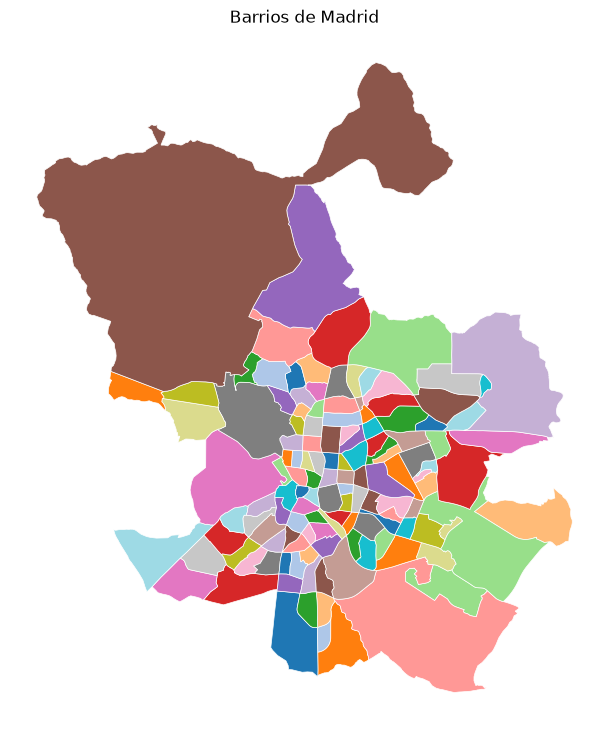

In [3]:
ax = barrios.plot(figsize=(9, 9), edgecolor="white", linewidth=0.5, cmap="tab20", column=barrios.index % 20)
ax.set_axis_off()
ax.set_title("Barrios de Madrid")

In [6]:
m = barrios.explore(column="NOMDIS", tooltip=["NOMBRE", "NOMDIS"])
m.save("../data/interim/mapa_barrios.html")

In [7]:
barrios_limpio = (
    barrios[["CODDIS", "NOMDIS", "COD_BAR", "NOMBRE", "geometry"]]
    .rename(columns={
        "CODDIS": "cod_distrito",
        "NOMDIS": "distrito",
        "COD_BAR": "cod_barrio",
        "NOMBRE": "barrio",
    })
)

# Códigos como texto con ceros a la izquierda: "01", "011"
barrios_limpio["cod_distrito"] = barrios_limpio["cod_distrito"].astype(int).astype(str).str.zfill(2)
barrios_limpio["cod_barrio"] = barrios_limpio["cod_barrio"].astype(int).astype(str).str.zfill(3)

# Superficie en km² (el CRS está en metros)
barrios_limpio["area_km2"] = barrios_limpio.geometry.area / 1e6

barrios_limpio.head()

,cod_distrito,distrito,cod_barrio,barrio,geometry,area_km2
0,17,Villaverde,171,Villaverde Alto - Casco Histórico de Villaverde,"POLYGON ((441017.489 4466354.375, 441050.818 4...",9.254048
1,17,Villaverde,172,San Cristóbal,"POLYGON ((441224.682 4464925.894, 441171.808 4...",1.082492
2,17,Villaverde,173,Butarque,"POLYGON ((444144.707 4464513.034, 444144.856 4...",6.381764
3,17,Villaverde,174,Los Rosales,"POLYGON ((441941.844 4466974.287, 441930.867 4...",1.540747
4,17,Villaverde,175,Ángeles,"POLYGON ((441076.001 4468448.76, 441105.538 44...",1.935272


In [8]:
print("Barrios:", len(barrios_limpio))                                   # 131
print("Distritos:", barrios_limpio["cod_distrito"].nunique())           # 21
print("Códigos de barrio únicos:", barrios_limpio["cod_barrio"].is_unique)  # True
print("Geometrías válidas:", barrios_limpio.is_valid.all())             # True
print("Superficie total (km²):", round(barrios_limpio["area_km2"].sum(), 1))  # ~604

Barrios: 131
Distritos: 21
Códigos de barrio únicos: True
Geometrías válidas: True
Superficie total (km²): 604.0


In [9]:
from pathlib import Path

PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

barrios_limpio.to_parquet(PROCESSED / "barrios.parquet")
print("Guardado:", PROCESSED / "barrios.parquet")

Guardado: ..\data\processed\barrios.parquet
